In [112]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import os, glob
import pandas as pd

In [98]:
import matplotlib as mpl
import matplotlib.font_manager as fm

FONT_DIR = os.path.expanduser("~/fonts/SourceSans3")

for f in glob.glob(os.path.join(FONT_DIR, "*.ttf")):
    fm.fontManager.addfont(f)

available = {f.name for f in fm.fontManager.ttflist}
FAMILY = next((n for n in ("Source Sans 3", "Source Sans Pro") if n in available), None)
if FAMILY is None:
    raise RuntimeError(f"Source Sans not found. Check FONT_DIR: {FONT_DIR}")

W = 418.25372 / 72.27   # \textwidth in inches (~5.787)
W_HALF = 0.48 * W       # two panels side by side

mpl.rcParams.update({
    # --- Text / fonts ---
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [FAMILY],
    "mathtext.fontset": "custom",
    "mathtext.rm": FAMILY,
    "mathtext.it": f"{FAMILY}:italic",
    "mathtext.bf": f"{FAMILY}:bold",
    "mathtext.sf": FAMILY,
    "mathtext.default": "it",
    "mathtext.fallback": "cm",     
    "axes.unicode_minus": True,    

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 10,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,

    "legend.frameon": False,
    "legend.handlelength": 1.5,

    "figure.figsize": (W, W),
    "figure.constrained_layout.use": True,
    "savefig.dpi": 300,             
    "savefig.format": "pdf",
    "pdf.fonttype": 42,    
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [99]:
run = '2024/oper_08'

In [100]:
path = '/jetfs/scratch/psplechtna/thesisdata/oper/'


In [122]:
data = xr.open_dataset(path+run+'_temporal_evol.nc')
reference = xr.open_dataset(path+'1991-2020/1991_temporal_evol.nc')

In [123]:
reference_mean = reference.mean(dim='release_time')
reference_std = reference.std(dim='release_time')

In [ ]:
release = 4
data=data.isel(release_time=release)

In [125]:
t_release=pd.Timestamp(data.release_time.values)

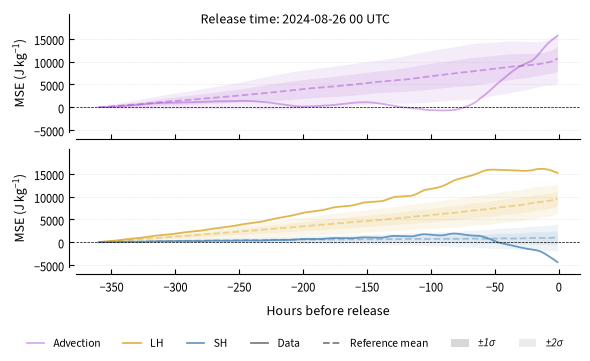

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def plot_var(ax, name, color, label, alpha=0.8):
    m, s = reference_mean[name], reference_std[name]
    ax.plot(xes, data[name], color=color, ls='-', alpha=alpha, label=label)
    ax.plot(xes, m, color=color, ls='--', alpha=0.4)
    for n, a in [(1, 0.1), (2, 0.09)]:
        ax.fill_between(xes, m - n*s, m + n*s, color=color, alpha=a, linewidth=0)

fig, ax = plt.subplots(2, 1, figsize=(W, 0.6*W), sharex=True)

plot_var(ax[0], 'advection', 'darkorchid', 'Advection', alpha=0.4)
plot_var(ax[1], 'flux_lh', 'goldenrod', 'LH')
plot_var(ax[1], 'flux_sh', 'steelblue', 'SH')

# one entry per color (collected from both axes)
handles, labels = [], []
for a in ax:
    h, l = a.get_legend_handles_labels()
    handles += h; labels += l
    a.grid(ls=':', alpha=0.5, axis='y')
    a.axhline(0, color='k', ls='--', lw=0.5)
    a.set_ylim(-5500, 20500)
    a.set_yticks(np.arange(-5000, 20000, 5000))
    a.set_ylabel(r'MSE ($\mathrm{J\,kg^{-1}}$)')
    for spine in ['top', 'right']:
        a.spines[spine].set_visible(False)
    spine_offset = 5
    a.spines.left.set_position(('outward', spine_offset))
    a.spines.bottom.set_position(('outward', spine_offset))

ax[1].set_xlabel('Hours before release')

# one entry per style, in neutral gray
style_handles = [
    Line2D([], [], color='gray', ls='-',  label='Data'),
    Line2D([], [], color='gray', ls='--', label='Reference mean'),
    Patch(facecolor='gray', alpha=0.30, label=r'$\pm 1\sigma$'),
    Patch(facecolor='gray', alpha=0.15, label=r'$\pm 2\sigma$'),
]
all_handles = handles + style_handles
ncol = 7
reordered = [h for i in range(ncol) for h in all_handles[i::ncol]]

fig.suptitle(f'Release time: {t_release:%Y-%m-%d %H} UTC', y=1)
fig.legend(handles=reordered, ncol=ncol, fontsize='small',
             loc='outside lower center')
#fig.savefig('plots/temporal_evol.pdf')